# WellSense · Notebook 0 — Data Preparation (from Petrobras's official files)
This notebook shows **exactly how the approved working dataset (`data/3W_real_small.csv`) was produced** from Petrobras's official 3W files, and **why** each reduction step was taken.

| Step | What | Why (short) |
|---|---|---|
| 0 | Download Petrobras 3W v2.0.0, pinned to one exact version | Reproducible: anyone gets the same files |
| 1 | Keep **real** instances only | The project requires real company data |
| 2 | Keep **one reading per minute** | 33 million rows → 0.55 million, without changing what the faults look like |
| 3 | Keep **up to 15 instances per event type**, spread across wells | Balanced: no event type dominates, more wells represented |
| 4 | Keep **5 h before to 15 h after** each fault starts | Keeps the normal baseline and the fault itself, drops days of repetitive tail |

**Nothing is cleaned here.** Missing values, error codes and frozen sensors are left exactly as Petrobras published them — cleaning is the job of Notebook 1 (ETL).

At the end, the rebuilt file is compared with the approved file to prove they are identical.

## Setup
Same options as Notebook 1: `SOURCE = 'drive'` if the `WellSense` folder is in this account's Google Drive, or `'upload'` to upload the project zip.
The raw Petrobras files (~500 MB) are downloaded to Colab's temporary disk, not to your Drive.

In [1]:
SOURCE = 'drive'          # 'drive' or 'upload'

import os, sys, zipfile, subprocess

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not IN_COLAB:
    PROJECT_DIR = os.getcwd()
elif SOURCE == 'drive':
    from google.colab import drive
    drive.mount('/content/drive')
    # Find the WellSense folder, even if it ended up one level deeper (e.g. MyDrive/WellSense/WellSense)
    import glob
    _cands = ['/content/drive/MyDrive/WellSense'] + sorted(glob.glob('/content/drive/MyDrive/WellSense*')) \
             + sorted(glob.glob('/content/drive/MyDrive/*/WellSense*'))
    _cands += [c + '/WellSense' for c in list(_cands)]
    _found = [c for c in _cands if os.path.isfile(os.path.join(c, 'wellsense', '__init__.py'))]
    if not _found:
        raise FileNotFoundError("WellSense folder not found in My Drive. Upload the WHOLE unzipped WellSense folder "
                                "(it must contain the folders 'wellsense', 'data' and 'knowledge_base') to My Drive.")
    PROJECT_DIR = _found[0]
    print('Project folder:', PROJECT_DIR)
else:
    from google.colab import files
    PROJECT_DIR = '/content/WellSense'
    if not os.path.exists(PROJECT_DIR):
        print('Choose the WellSense zip file from your computer...')
        for name in files.upload():
            zipfile.ZipFile(name).extractall('/content')
            os.remove(name)

os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)
for d in ['data', 'outputs/figures', 'outputs/tables']:
    os.makedirs(d, exist_ok=True)
RAW_DIR = '/content/3W_official' if IN_COLAB else os.path.abspath('raw_3w')
print('Project folder:', os.getcwd())
print('Raw Petrobras files will go to:', RAW_DIR)

Project folder: /content/drive/MyDrive/WellSense
Raw Petrobras files will go to: /content/drive/MyDrive/WellSense/raw_3w


In [2]:
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False})

# Set to False to skip writing the 87 MB "all instances, 1 per minute" CSV
SAVE_FULL_1MIN = True

## Step 0 — Download the official Petrobras data
* Source: https://github.com/petrobras/3W (license CC BY 4.0), dataset version **2.0.0**.
* Pinned to commit `82cebb46…` so the files can never change under us, even if Petrobras adds data later.
* Only the real-instance files are downloaded (`WELL-*.parquet`), plus the official configuration file.

In [3]:
REPO = 'https://github.com/petrobras/3W.git'
COMMIT = '82cebb46190186f42e7d9c333c9756357e41ef20'

def git(*args):
    subprocess.run(['git', '-C', RAW_DIR, *args], check=True)

if not glob.glob(os.path.join(RAW_DIR, 'dataset', '*', 'WELL-*.parquet')):
    subprocess.run(['git', 'init', '-q', RAW_DIR], check=True)
    git('remote', 'add', 'origin', REPO)
    git('sparse-checkout', 'set', '--no-cone', '/dataset/*/WELL-*.parquet', '/dataset/dataset.ini')
    git('fetch', '-q', '--depth', '1', '--filter=blob:none', 'origin', COMMIT)
    git('checkout', '-q', 'FETCH_HEAD')
    print('Downloaded.')
else:
    print('Already downloaded.')

head = subprocess.run(['git', '-C', RAW_DIR, 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip()
print('Petrobras commit:', head)
print(open(os.path.join(RAW_DIR, 'dataset', 'dataset.ini')).read().split('[VERSION]')[1].split('\n\n')[0].strip())

Already downloaded.
Petrobras commit: 82cebb46190186f42e7d9c333c9756357e41ef20
# 3W Dataset version (may be different than 3W Toolkit version)
DATASET = 2.0.0


## Step 1 — Keep real instances only
The official dataset mixes three kinds of instances. Their file names tell them apart:

| File name starts with | Source |
|---|---|
| `WELL-` | **Real** data recorded on Petrobras wells |
| `SIMULATED_` | Generated by a flow simulator |
| `DRAWN_` | Drawn by hand by Petrobras experts |

**Why:** our teacher requires data from a real company, and only real instances contain the genuine problems (missing values, frozen sensors, error codes) that the ETL must handle — Petrobras states that simulated and hand-drawn instances have no frozen variables or missing values (Vargas et al., 2025).

In [4]:
all_files = subprocess.run(['git', '-C', RAW_DIR, 'ls-tree', '-r', '--name-only', 'HEAD', 'dataset'],
                           capture_output=True, text=True).stdout.split()
all_files = [f for f in all_files if f.endswith('.parquet')]
kind = pd.Series([os.path.basename(f).split('-')[0].split('_')[0] for f in all_files]).map(
    {'WELL': 'real', 'SIMULATED': 'simulated', 'DRAWN': 'hand-drawn'})
print('All instances in the official dataset:'); print(kind.value_counts().to_string())

real_files = sorted(glob.glob(os.path.join(RAW_DIR, 'dataset', '*', 'WELL-*.parquet')),
                    key=lambda p: (int(os.path.basename(os.path.dirname(p))), os.path.basename(p)))
print(f'\nKept: {len(real_files)} real instances')

All instances in the official dataset:
real          1119
simulated     1089
hand-drawn      20

Kept: 1119 real instances


## Step 2 — One reading per minute
Petrobras records **one reading per second**. For 1,119 real instances that is about **33 million rows** (≈ 6–8 GB as CSV) — too big for Excel, slow in Colab, and painful to share.

We keep the **first raw reading of every minute**. Why this is safe:
* The events develop over **minutes to days**. Petrobras's own monitoring experts confirm them by looking at time windows of **5 minutes to 72 hours** — never single seconds (Vargas, 2019, Table 1; see Step 4). The KBS also looks at changes over **15–30 minutes**, so one reading per minute is more than enough.
* We **pick** an actual reading instead of **averaging** a minute. Averaging would smooth away the very problems the ETL must find (spikes, error codes, frozen values).
* Even the fastest event (a safety valve closing) still shows clearly as a sudden jump between two minutes — see the plot below.

The output of this step is also saved as `data/3W_real_instances_1min.csv` (all 1,119 instances), used for the final evaluation.

In [5]:
EVENT_NAMES = ['NORMAL', 'ABRUPT_INCREASE_OF_BSW', 'SPURIOUS_CLOSURE_OF_DHSV', 'SEVERE_SLUGGING',
               'FLOW_INSTABILITY', 'RAPID_PRODUCTIVITY_LOSS', 'QUICK_RESTRICTION_IN_PCK', 'SCALING_IN_PCK',
               'HYDRATE_IN_PRODUCTION_LINE', 'HYDRATE_IN_SERVICE_LINE']
VARS = ['ABER-CKGL', 'ABER-CKP', 'ESTADO-DHSV', 'ESTADO-M1', 'ESTADO-M2', 'ESTADO-PXO', 'ESTADO-SDV-GL',
        'ESTADO-SDV-P', 'ESTADO-W1', 'ESTADO-W2', 'ESTADO-XO', 'P-ANULAR', 'P-JUS-BS', 'P-JUS-CKGL',
        'P-JUS-CKP', 'P-MON-CKGL', 'P-MON-CKP', 'P-MON-SDV-P', 'P-PDG', 'PT-P', 'P-TPT', 'QBS', 'QGL',
        'T-JUS-CKP', 'T-MON-CKP', 'T-PDG', 'T-TPT']
COLUMNS = ['instance_id', 'well_id', 'event_type', 'event_name', 'timestamp'] + VARS + ['class', 'state']

def one_per_minute(path):
    raw = pd.read_parquet(path)
    ts = raw.index.to_series()
    minute = ts.dt.floor('min')
    keep = (minute != minute.shift()).values          # first reading of each new minute
    out = raw.loc[keep].reset_index()
    event = int(os.path.basename(os.path.dirname(path)))
    name = os.path.basename(path).replace('.parquet', '')
    out.insert(0, 'instance_id', name)
    out.insert(1, 'well_id', name[:10])
    out.insert(2, 'event_type', event)
    out.insert(3, 'event_name', EVENT_NAMES[event])
    for c in VARS:
        if c not in out:
            out[c] = np.nan
    return out[COLUMNS], len(raw)

parts, seconds = [], 0
for i, p in enumerate(real_files):
    part, n = one_per_minute(p)
    parts.append(part)
    seconds += n
    if (i + 1) % 200 == 0:
        print(f'  read {i + 1}/{len(real_files)} files')
full = pd.concat(parts, ignore_index=True)
full['timestamp'] = full['timestamp'].dt.strftime('%Y-%m-%d %H:%M:%S')
print(f'Rows at 1 reading per second : {seconds:,}')
print(f'Rows at 1 reading per minute : {len(full):,}  ({len(full) / seconds:.1%} of the original)')

if SAVE_FULL_1MIN:
    full.to_csv('data/3W_real_instances_1min.csv', index=False)
    print('Saved data/3W_real_instances_1min.csv')

  read 200/1119 files
  read 400/1119 files
  read 600/1119 files
  read 800/1119 files
  read 1000/1119 files
Rows at 1 reading per second : 32,872,250
Rows at 1 reading per minute : 549,063  (1.7% of the original)
Saved data/3W_real_instances_1min.csv


### Does one reading per minute change what a fault looks like?
A real safety-valve (DHSV) closure, plotted at full 1-second resolution and at the 1-minute readings we keep.

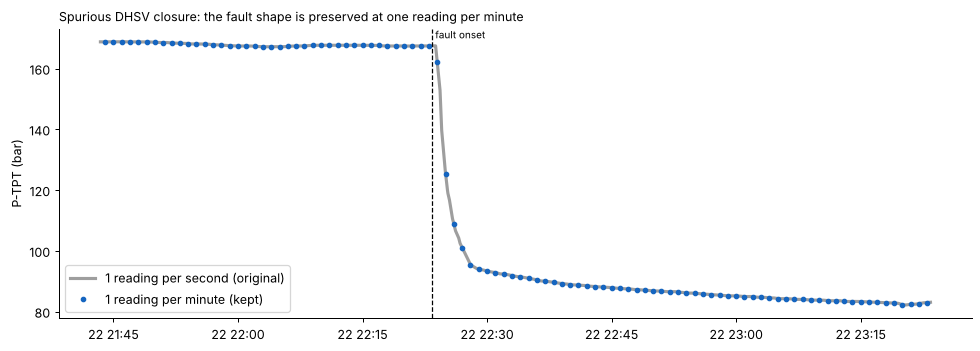

In [6]:
ex = os.path.join(RAW_DIR, 'dataset', '2', 'WELL-00003_20141122190000.parquet')
sec = pd.read_parquet(ex)
mins = full[full.instance_id == 'WELL-00003_20141122190000']
onset = sec.index[(sec['class'].fillna(0) != 0)][0]
win = (sec.index > onset - pd.Timedelta('40min')) & (sec.index < onset + pd.Timedelta('60min'))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(sec.index[win], sec.loc[win, 'P-TPT'] / 1e5, color='#9e9e9e', lw=2.5, label='1 reading per second (original)')
mw = pd.to_datetime(mins.timestamp)
m = (mw > onset - pd.Timedelta('40min')) & (mw < onset + pd.Timedelta('60min'))
ax.plot(mw[m], mins.loc[m, 'P-TPT'] / 1e5, 'o', ms=3.5, color='#1565c0', label='1 reading per minute (kept)')
ax.axvline(onset, color='k', ls='--', lw=1); ax.text(onset, ax.get_ylim()[1], ' fault onset', va='top', fontsize=8)
ax.set_ylabel('P-TPT (bar)'); ax.legend(loc='lower left')
ax.set_title('Spurious DHSV closure: the fault shape is preserved at one reading per minute', loc='left', fontsize=10)
plt.tight_layout(); plt.savefig('outputs/figures/00_second_vs_minute.png', dpi=150); plt.show()

## Step 3 — Up to 15 instances per event type, spread across wells
The real data is very unbalanced:

In [7]:
per_type = full.groupby(['event_type', 'event_name']).agg(
    instances=('instance_id', 'nunique'), wells=('well_id', 'nunique')).reset_index()
per_type

,event_type,event_name,instances,wells
0,0,NORMAL,594,9
1,1,ABRUPT_INCREASE_OF_BSW,4,3
2,2,SPURIOUS_CLOSURE_OF_DHSV,22,7
3,3,SEVERE_SLUGGING,32,2
4,4,FLOW_INSTABILITY,343,7
5,5,RAPID_PRODUCTIVITY_LOSS,11,3
6,6,QUICK_RESTRICTION_IN_PCK,6,2
7,7,SCALING_IN_PCK,36,6
8,8,HYDRATE_IN_PRODUCTION_LINE,14,9
9,9,HYDRATE_IN_SERVICE_LINE,57,15


**Why limit to 15:**
* Two types (NORMAL with 594 and FLOW_INSTABILITY with 343) would make up over 80% of the data. A system tested mostly on those two would look good while being poor at the rare, dangerous faults.
* 15 per type keeps every type visible, keeps the file small enough to work with, and still gives several real examples of each fault.
* Rare types (4–14 instances) keep **all** their instances.

**How the 15 are chosen — fairly, not cherry-picked:** instances are taken in turns from each well (first instance of every well, then the second of every well, …). This is fixed and repeatable, and spreads the sample over as many different wells as possible.

The **full** set of 1,119 instances is still used for the final evaluation (Notebook 4), so nothing is hidden.

In [8]:
MAX_PER_TYPE = 15
chosen = []
for et, g in full.groupby('event_type'):
    inst = g.drop_duplicates('instance_id')[['instance_id', 'well_id']].copy()
    inst['turn'] = inst.groupby('well_id').cumcount()          # 0 = that well's 1st instance, 1 = 2nd, ...
    chosen += list(inst.sort_values(['turn', 'well_id']).head(MAX_PER_TYPE)['instance_id'])
selected = full[full.instance_id.isin(chosen)]

step3 = per_type.assign(
    selected=lambda t: t.event_type.map(selected.groupby('event_type').instance_id.nunique()),
    wells_in_selection=lambda t: t.event_type.map(selected.groupby('event_type').well_id.nunique()))
step3

,event_type,event_name,instances,wells,selected,wells_in_selection
0,0,NORMAL,594,9,15,9
1,1,ABRUPT_INCREASE_OF_BSW,4,3,4,3
2,2,SPURIOUS_CLOSURE_OF_DHSV,22,7,15,7
3,3,SEVERE_SLUGGING,32,2,15,2
4,4,FLOW_INSTABILITY,343,7,15,7
5,5,RAPID_PRODUCTIVITY_LOSS,11,3,11,3
6,6,QUICK_RESTRICTION_IN_PCK,6,2,6,2
7,7,SCALING_IN_PCK,36,6,15,6
8,8,HYDRATE_IN_PRODUCTION_LINE,14,9,14,9
9,9,HYDRATE_IN_SERVICE_LINE,57,15,15,15


## Step 4 — Keep the part of each instance that matters
Some instances are very long because the fault stays in place for days (e.g. scaling, hydrates). After the fault has developed, hours of nearly identical readings add nothing new.

For each **fault** instance we keep a window around the **fault onset** (the first minute Petrobras labelled as abnormal):
* **5 hours before** — the well's normal behaviour (the ETL uses the first hour as that well's baseline) and a long normal stretch to measure false alarms
* **15 hours after** — the fault developing and becoming established

For **normal** instances we keep the first **10 hours**.

**Why 15 hours is enough** — the time windows Petrobras experts use to confirm each event (Vargas, 2019, Table 1):

| Event | Expert window |
|---|---|
| Spurious DHSV closure | 5–20 min |
| Flow instability, quick restriction in PCK | 15 min |
| Hydrate in production line | 30 min – 5 h |
| Severe slugging | 5 h |
| Abrupt increase of BSW, rapid productivity loss | 12 h |
| Scaling in PCK | 72 h |

15 hours after onset covers every event except scaling, which develops over days. For scaling, the first 15 hours of development are kept; the complete instances remain in the 1-minute file for evaluation. *(Limitation to mention in the report.)*

In [9]:
BEFORE, AFTER, NORMAL_LEN = 300, 900, 600     # minutes
pieces = []
for iid, g in selected.groupby('instance_id', sort=False):
    g = g.reset_index(drop=True)
    abnormal = g.index[g['class'].notna() & (g['class'] != 0)]
    if g['event_type'].iat[0] == 0 or len(abnormal) == 0:
        pieces.append(g.head(NORMAL_LEN))
    else:
        start = abnormal[0]
        pieces.append(g.iloc[max(0, start - BEFORE): start + AFTER])
small = pd.concat(pieces, ignore_index=True)

lengths = pd.DataFrame({
    'avg_minutes_per_instance_before': selected.groupby('event_name').size() / selected.groupby('event_name').instance_id.nunique(),
    'rows_before': selected.groupby('event_name').size(),
    'rows_after': small.groupby('event_name').size(),
}).round(0).astype(int)
lengths

,avg_minutes_per_instance_before,rows_before,rows_after
event_name,,,
ABRUPT_INCREASE_OF_BSW,988,3952,2294
FLOW_INSTABILITY,180,2707,2707
HYDRATE_IN_PRODUCTION_LINE,5726,80164,16800
HYDRATE_IN_SERVICE_LINE,559,8383,7001
NORMAL,434,6514,4726
QUICK_RESTRICTION_IN_PCK,216,1295,1284
RAPID_PRODUCTIVITY_LOSS,667,7333,5910
SCALING_IN_PCK,4932,73979,16150
SEVERE_SLUGGING,356,5335,5335


## Save and verify
The result is written to `outputs/tables/3W_real_small_rebuilt.csv` and compared value-by-value with the approved file `data/3W_real_small.csv`.

In [10]:
small.to_csv('outputs/tables/3W_real_small_rebuilt.csv', index=False)

if os.path.exists('data/3W_real_small.csv'):
    approved = pd.read_csv('data/3W_real_small.csv', low_memory=False)
    rebuilt = pd.read_csv('outputs/tables/3W_real_small_rebuilt.csv', low_memory=False)
    pd.testing.assert_frame_equal(approved, rebuilt, check_dtype=False)
    print(f'IDENTICAL: the rebuilt file matches the approved dataset exactly '
          f'({len(rebuilt):,} rows × {rebuilt.shape[1]} columns, every value).')
else:
    small.to_csv('data/3W_real_small.csv', index=False)
    print('No approved file found, so the rebuilt file was saved as data/3W_real_small.csv')

IDENTICAL: the rebuilt file matches the approved dataset exactly (65,846 rows × 34 columns, every value).


## Summary: from Petrobras's files to our working dataset

In [11]:
funnel = pd.DataFrame([
    ('Official 3W dataset (real + simulated + hand-drawn)', len(all_files), None),
    ('Step 1: real instances only', len(real_files), seconds),
    ('Step 2: one reading per minute', len(real_files), len(full)),
    ('Step 3: up to 15 instances per event type', selected.instance_id.nunique(), len(selected)),
    ('Step 4: window around each fault', small.instance_id.nunique(), len(small)),
], columns=['stage', 'instances', 'rows'])
funnel['rows'] = funnel['rows'].astype('Int64')
funnel.to_csv('outputs/tables/data_preparation_funnel.csv', index=False)
funnel

,stage,instances,rows
0,Official 3W dataset (real + simulated + hand-d...,2228,<NA>
1,Step 1: real instances only,1119,32872250
2,Step 2: one reading per minute,1119,549063
3,Step 3: up to 15 instances per event type,125,193301
4,Step 4: window around each fault,125,65846


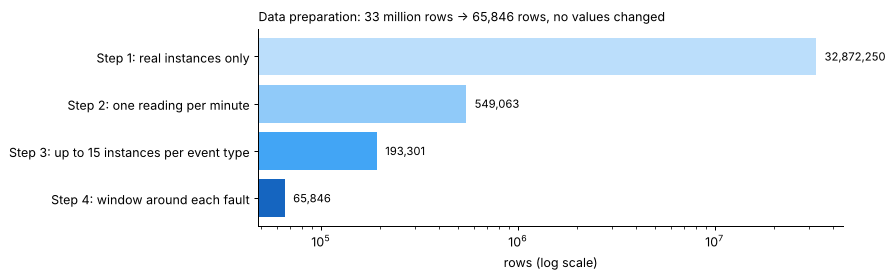

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.2))
f = funnel.dropna().astype({'rows': 'int64'})
ax.barh(f.stage[::-1], f.rows[::-1], color=['#1565c0', '#42a5f5', '#90caf9', '#bbdefb'])
ax.set_xscale('log'); ax.set_xlabel('rows (log scale)')
for y, v in enumerate(f.rows[::-1]):
    ax.text(v * 1.1, y, f'{int(v):,}', va='center', fontsize=9)
ax.set_title('Data preparation: 33 million rows → 65,846 rows, no values changed', loc='left', fontsize=10)
plt.tight_layout(); plt.savefig('outputs/figures/00_preparation_funnel.png', dpi=150); plt.show()

**What to say if asked "why did you reduce the data?"**
1. **Only real data** — the project requires real company data; simulated data has no real-world problems to clean.
2. **One reading per minute** — the faults develop over minutes to days; Petrobras experts themselves confirm them over 5-minute to 72-hour windows, and the KBS reasons over 15–30 minute windows. Per-second data adds size without adding information (the plot shows the fault looks the same).
3. **Up to 15 per type** — keeps all fault types balanced and fairly sampled across wells, instead of 80% normal/flow-instability.
4. **Window around the fault** — 5 h before (normal baseline) + 15 h after, which covers the expert confirmation window of every event except slow scaling; drops days of repetitive readings.

And: **no value was cleaned or changed** — every reading in the working file is an original Petrobras reading. The full set (all 1,119 instances) is kept for the final evaluation.

**References**
* Vargas, R.E.V. (2019). *Base de dados e benchmarks para prognóstico de anomalias em sistemas de elevação de petróleo* (Doctoral thesis). Universidade Federal do Espírito Santo. https://github.com/ricardovvargas/3w_dataset
* Vargas, R.E.V. et al. (2025). *3W Dataset 2.0.0: a realistic and public dataset with rare undesirable real events in oil wells*. arXiv:2507.01048.
* Petrobras (2024). *3W Project* (dataset v2.0.0, CC BY 4.0). https://github.com/petrobras/3W